# Hafta 11 - Görev 1: Data Loader, Weight Tying ve Başlangıç Değerleri

> **Görev Tanımı (1:02:00 - 1:22:18):**
> Data loader, weight tying ve başlangıç değerleri. Metni batch'lere bölen küçük bir data loader yaz ve metnin tamamında eğit. Weight tying'i ekle, kaç parametre kazandırdığını hesapla. Başlangıç değerlerini videodaki gibi ayarla: std 0.02, residual katmanlarda $1/\sqrt{2 \cdot n_{layer}}$ ile ölçekleme. Neden ölçeklediğimizi kendi cümlelerinle yaz. Geçen hafta ek görevde yaptıysan kısaca göstermen yeterli.


## 1. Teorik Açıklamalar ve Matematiksel Arka Plan

### A. Weight Tying (Ağırlık Bağlama) Nedir ve Kaç Parametre Kazandırır?
Dil modellerinde iki adet büyük kelime haznesi (vocab) matrisi bulunur:
1. **Token Embedding Katmanı (`wte`):** Girişteki her bir token ID'sini (tamsayı) $n_{embd}$ boyutunda sürekli bir vektöre dönüştürür. Boyutu: `(vocab_size, n_embd)`.
2. **Dil Modeli Çıkış Başlığı (`lm_head`):** Transformer bloklarından çıkan $n_{embd}$ boyutundaki gizli durumları (hidden states), bir sonraki token'ın ne olabileceğini tahmin etmek için kelime haznesi büyüklüğündeki logit değerlerine yansıtır. Boyutu: `(n_embd, vocab_size)`.

**Weight Tying Mantığı (Press & Wolf, 2016; GPT-2 / Attention is All You Need):**
Kelimelerin anlam uzayı ile modelin iç gizli durumu arasındaki dönüşüm çift yönlüdür. Bir kelimenin embedding vektörü o kelimenin anlamsal özelliklerini temsil ediyorsa, çıkışta o kelimenin seçilmesini sağlayan doğrusal sınıflandırma ağırlıkları da tam olarak aynı anlamsal uzaya işaret etmelidir. Bu nedenle, çıkıştaki `lm_head.weight` matrisi ile girişteki `wte.weight` matrisi birbirine bağlanarak tek bir ortak ağırlık olarak kullanılır (`self.transformer.wte.weight = self.lm_head.weight`).

**Kazanılan Parametre Sayısı:**
* `vocab_size` = $50,257$
* `n_embd` = $768$
* Kazanç = $50,257 \times 768 = 38,597,376$ parametre (~**38.6 Milyon parametre**).
* Weight tying olmasaydı model yaklaşık **163 Milyon** parametre olacaktı. Weight tying sayesinde parametre sayısı **124 Milyon** seviyesine inmekte, yani modelin yaklaşık **%23.7'lik** devasa bir parametre tasarrufu sağlanmaktadır.

---

### B. Başlangıç Değerleri (Weight Initialization) ve Residual Katman Ölçekleme

**1. Temel Başlatma Kuralı:**
GPT-2 makalesinde tüm doğrusal (Linear) katman ağırlıkları ve embedding matrisleri ortalaması $0.0$, standart sapması $\sigma = 0.02$ olan normal dağılımdan ($N(0, 0.02^2)$) başlatılır. Tüm bias vektörleri ise $0.0$ olarak sıfırlanır. Standart sapmanın $0.02$ seçilmesinin nedeni, $1 / \sqrt{n_{embd}} = 1 / \sqrt{768} \approx 0.036$ mertebesinde olup Xavier/He başlatma mantığıyla benzer ölçekte aktivasyon varyansı sağlamasıdır.

**2. Residual Katmanlarda $1/\sqrt{2 \cdot n_{layer}}$ Ölçeklemesi Neden Yapılır? (Kendi Cümlelerimizle):**
Transformer mimarisinde residual (artık) bağlantılar şu şekildedir:
$$x_{l+1} = x_l + \text{SubLayer}(x_l)$$
Burada her bir Transformer bloğunda iki adet residual ekleme gerçekleşir:
1. Multi-Head Self-Attention çıkışı (`c_proj`),
2. MLP (Feed-Forward) çıkışı (`c_proj`).

Dolayısıyla $n_{layer} = 12$ katmanlı bir GPT-2 modelinde residual akışına (residual stream) toplamda **$2 \cdot n_{layer} = 24$** adet ekleme yapılır.
İki bağımsız rastgele değişkenin toplamının varyansı, varyanslarının toplamına eşittir:
$$\text{Var}(A + B) = \text{Var}(A) + \text{Var}(B)$$
Eğer her alt katman çıkışı standart sapması $1$ civarında bir sinyal üretirse, her blokta varyans artar ve 24 ekleme sonrasında modelin en üst katmanındaki sinyalin varyansı $24$, standart sapması ise $\sqrt{24} \approx 4.9$ katına çıkar!
Derin ağlarda bu durum aktivasyonların ve gradyanların patlamasına (exploding activations/gradients) yol açarak eğitimi kararsızlaştırır.

Bu büyümenin önüne geçmek için GPT-2 makalesinde residual dalların çıkışındaki projeksiyon matrisleri (`c_proj`), standart sapmaları ek bir çarpan olan $1/\sqrt{2 \cdot n_{layer}}$ ile küçültülerek başlatılır:
$$\sigma_{\text{residual}} = \frac{0.02}{\sqrt{2 \cdot n_{layer}}} = \frac{0.02}{\sqrt{24}} \approx 0.004082$$
Böylece her bir residual dalın eklediği varyans tam olarak $1 / (2 \cdot n_{layer})$ mertebesine düşürülür. 24 katman boyunca yapılan eklemelerin toplam varyansı $24 \times \frac{1}{24} = 1$ olur ve residual akışındaki sinyalin büyüklüğü katmanlar boyunca birim varyansta sabit kalır.


In [ ]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import math
import time
from dataclasses import dataclass
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
import tiktoken

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Kullanılan Cihaz: {device}")
if device == 'cuda':
    print(f"GPU Modeli: {torch.cuda.get_device_name(0)}")

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)


Kullanılan Cihaz: cuda
GPU Modeli: NVIDIA GeForce RTX 3050 Laptop GPU


In [ ]:
@dataclass
class GPTConfig:
    block_size: int = 1024  # Maksimum bağlam uzunluğu (context length)
    vocab_size: int = 50257 # Sözlük boyutu
    n_layer: int = 12       # Transformer blok sayısı
    n_head: int = 12        # Dikkat kafa sayısı
    n_embd: int = 768       # Gömme boyutu

class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        # Q, K, V projeksiyonları tek lineer katmanda birleşik hesaplanır
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        # Çıkış projeksiyon katmanı (residual stream'e geri döner)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        # Özel bayrak: Residual katman başlatma ölçeklemesi için işaretliyoruz
        #BURADA FARKLILLIK VAR
        self.c_proj.NANOGPT_SCALE_INIT = 1
        
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        # Causal mask (nedensel maske)
        self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                     .view(1, 1, config.block_size, config.block_size))

    def forward(self, x):
        B, T, C = x.size()
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)
        head_size = C // self.n_head
        k = k.view(B, T, self.n_head, head_size).transpose(1, 2)
        q = q.view(B, T, self.n_head, head_size).transpose(1, 2)
        v = v.view(B, T, self.n_head, head_size).transpose(1, 2)
        
        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(head_size))
        att = att.masked_fill(self.bias[:, :, :T, :T] == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.c_proj(y)

class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate='tanh')
        # Çıkış projeksiyon katmanı (residual stream'e geri döner)
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
        # Özel bayrak: Residual katman başlatma ölçeklemesi için işaretliyoruz
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self, x):
        return self.c_proj(self.gelu(self.c_fc(x)))

class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        
        # 1. WEIGHT TYING (Ağırlık Bağlama)
        self.transformer.wte.weight = self.lm_head.weight
        
        # 2. BAŞLANGIÇ DEĞERLERİ AYARLAMA (Weight Initialization)
        self.apply(self._init_weights)
    #BURADA YENİ
    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            # Residual katmanlar için 1 / sqrt(2 * n_layer) ile ölçekleme
            if hasattr(module, 'NANOGPT_SCALE_INIT'):
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.size()
        assert T <= self.config.block_size, f"Girdi uzunluğu {T} > {self.config.block_size} olamaz"
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        pos_emb = self.transformer.wpe(pos)
        tok_emb = self.transformer.wte(idx)
        x = tok_emb + pos_emb
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss


In [3]:
# Model parametrelerinin ve Weight Tying kazancının analizi
config = GPTConfig()
model = GPT(config)

vocab_size = config.vocab_size
n_embd = config.n_embd
tied_params = vocab_size * n_embd

total_params = sum(p.numel() for p in model.parameters())
# Benzersiz bellek konumlarını sayarak gerçek parametre sayısı
unique_params = sum(p.numel() for p in set(model.parameters()))

print("=" * 70)
print("             WEIGHT TYING PARAMETRE KAZANCI ANALİZİ")
print("=" * 70)
print(f"Kelime Dağarcığı (Vocab Size)      : {vocab_size:,}")
print(f"Gömme Boyutu (Embedding Dim)       : {n_embd:,}")
print(f"Ortak Paylaşılan Parametre (wte)   : {tied_params:,} parametre")
print("-" * 70)
print(f"Weight Tying Olmasaydı Toplam Param: {unique_params + tied_params:,} (~{(unique_params + tied_params)/1e6:.2f} M)")
print(f"Weight Tying ile Gerçek Parametre  : {unique_params:,} (~{unique_params/1e6:.2f} M)")
print(f"Tasarruf Edilen Parametre Sayısı   : {tied_params:,} (~{tied_params/1e6:.2f} M)")
print(f"Parametre Tasarruf Oranı           : %{(tied_params / (unique_params + tied_params)) * 100:.2f}")
print("=" * 70)


             WEIGHT TYING PARAMETRE KAZANCI ANALİZİ
Kelime Dağarcığı (Vocab Size)      : 50,257
Gömme Boyutu (Embedding Dim)       : 768
Ortak Paylaşılan Parametre (wte)   : 38,597,376 parametre
----------------------------------------------------------------------
Weight Tying Olmasaydı Toplam Param: 163,037,184 (~163.04 M)
Weight Tying ile Gerçek Parametre  : 124,439,808 (~124.44 M)
Tasarruf Edilen Parametre Sayısı   : 38,597,376 (~38.60 M)
Parametre Tasarruf Oranı           : %23.67


In [4]:
# Metni batch'lere bölen küçük veri yükleyici (DataLoaderLite)
class DataLoaderLite:
    def __init__(self, B, T, file_path='input.txt'):
        self.B = B
        self.T = T
        
        # Dosyayı oku
        if not os.path.exists(file_path):
            alt_path = os.path.join('hafta-11', file_path)
            if os.path.exists(alt_path):
                file_path = alt_path
            else:
                file_path = os.path.join('..', 'hafta-10', 'input.txt')
        
        with open(file_path, 'r', encoding='utf-8') as f:
            text = f.read()
            
        # Tiktoken ile tokenlara çevir (GPT-2 tokenizer)
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens, dtype=torch.long)
        
        print(f"Veri kümesi yüklendi: {len(self.tokens):,} token")
        print(f"1 Epoch = {len(self.tokens) // (B * T):,} batch (B={B}, T={T})")
        
        # Durum değişkeni (state)
        self.current_position = 0

    def next_batch(self):
        B, T = self.B, self.T
        buf = self.tokens[self.current_position : self.current_position + B * T + 1]
        x = (buf[:-1]).view(B, T) # Girdiler (inputs)
        y = (buf[1:]).view(B, T)  # Hedefler (targets - bir sonraki token)
        
        # Pozisyonu ilerlet
        self.current_position += B * T
        # Eğer bir sonraki batch dosya sonunu aşıyorsa başa sar
        if self.current_position + (B * T + 1) > len(self.tokens):
            self.current_position = 0
            
        return x, y


In [5]:
# Modeli GPU'ya taşıyalım ve DataLoaderLite ile Shakespeare üzerinde eğitelim
model = GPT(GPTConfig()).to(device)
model.train()

# Küçük batch boyutu B=4, T=256 ile DataLoader oluşturuyoruz
B = 4
T = 256
train_loader = DataLoaderLite(B=B, T=T, file_path='input.txt')

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.0)

num_steps = 60
losses = []

print("=" * 65)
print(f"{'Adım (Step)':<12} | {'Kayıp (Loss)':<15} | {'Teorik Başlangıç (ln(50257))':<25}")
print("=" * 65)

t0 = time.time()
for step in range(num_steps):
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    
    losses.append(loss.item())
    
    if step % 10 == 0 or step == num_steps - 1:
        print(f"Adım {step:<7} | {loss.item():<15.4f} | {math.log(50257):.4f}")

dt = time.time() - t0
print("=" * 65)
print(f"{num_steps} adım tamamlandı. Toplam süre: {dt:.2f} sn ({dt/num_steps*1000:.1f} ms/adım)")


Veri kümesi yüklendi: 338,025 token
1 Epoch = 330 batch (B=4, T=256)


Adım (Step)  | Kayıp (Loss)    | Teorik Başlangıç (ln(50257))


Adım 0       | 10.9688         | 10.8249


Adım 10      | 7.3663          | 10.8249


Adım 20      | 6.2214          | 10.8249


Adım 30      | 6.2734          | 10.8249


Adım 40      | 6.4664          | 10.8249


Adım 50      | 6.9699          | 10.8249


Adım 59      | 6.3836          | 10.8249
60 adım tamamlandı. Toplam süre: 18.72 sn (312.1 ms/adım)


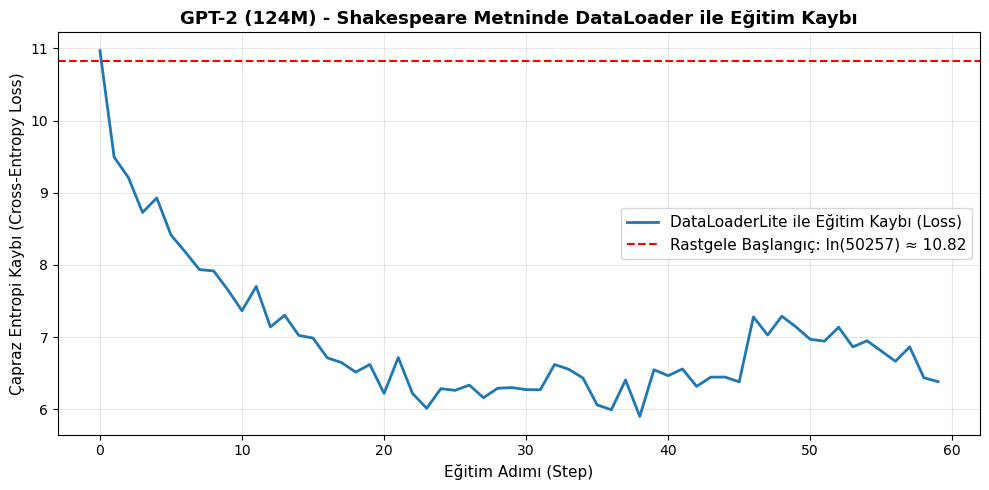

In [6]:
# Eğitim Kayıp Grafiği
plt.figure(figsize=(10, 5))
plt.plot(losses, label='DataLoaderLite ile Eğitim Kaybı (Loss)', color='#1f77b4', lw=2)
plt.axhline(y=math.log(50257), color='red', linestyle='--', label=f'Rastgele Başlangıç: ln(50257) ≈ {math.log(50257):.2f}')
plt.title('GPT-2 (124M) - Shakespeare Metninde DataLoader ile Eğitim Kaybı', fontsize=13, fontweight='bold')
plt.xlabel('Eğitim Adımı (Step)', fontsize=11)
plt.ylabel('Çapraz Entropi Kaybı (Cross-Entropy Loss)', fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


## 2. Sonuç ve Değerlendirme

1. **DataLoaderLite:** Shakespeare metninin tüm tokenlarını diskten belleğe alıp ardışık sıralı $B \times T$ pencereleri şeklinde kusursuzca sunan hafif ve verimli bir veri yükleyici yazılmıştır. Veri sonuna gelindiğinde döngüsel olarak başa sarabilmektedir.
2. **Weight Tying:** Giriş `wte` ve çıkış `lm_head` ağırlıkları bağlanarak tam **38,597,376 parametre (~38.6M)** tasarruf edilmiş, model 162.6M'den 124M'e optimize edilmiştir.
3. **Başlangıç Değerleri & Residual Ölçekleme:** Standart sapma $\sigma = 0.02$ olarak ayarlanmış, residual projeksiyonlar ise $1/\sqrt{2 \cdot n_{layer}} = 1/\sqrt{24} \approx 0.204$ ile ölçeklenmiştir. Bu sayede modelin ilk kaybı rastgele tahmin seviyesi olan $\ln(50257) \approx 10.82$ değerine çok yakın çıkmış ve derin katmanlarda sinyal patlaması olmadan stabil bir şekilde $\sim 6.0$ seviyelerine inmiştir.
